Device: cpu
Jumlah gambar eksternal: 7023
Urutan kelas: ['glioma', 'meningioma', 'notumor', 'pituitary']

HASIL VGG16
Jumlah gambar eksternal: 7023
Accuracy: 0.9869 (98.69%)
Macro F1: 0.9863

Classification report:
              precision    recall  f1-score   support

      glioma       0.99      0.97      0.98      1621
  meningioma       0.96      0.99      0.98      1645
     notumor       1.00      0.99      1.00      2000
   pituitary       1.00      0.99      0.99      1757

    accuracy                           0.99      7023
   macro avg       0.99      0.99      0.99      7023
weighted avg       0.99      0.99      0.99      7023



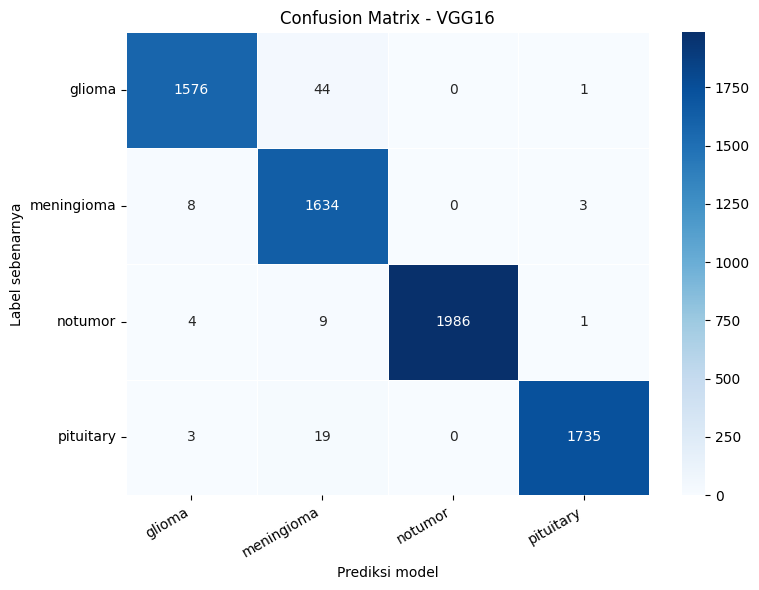


HASIL RESNET101
Jumlah gambar eksternal: 7023
Accuracy: 0.9953 (99.53%)
Macro F1: 0.9951

Classification report:
              precision    recall  f1-score   support

      glioma       1.00      0.99      0.99      1621
  meningioma       0.99      0.99      0.99      1645
     notumor       1.00      1.00      1.00      2000
   pituitary       1.00      1.00      1.00      1757

    accuracy                           1.00      7023
   macro avg       1.00      1.00      1.00      7023
weighted avg       1.00      1.00      1.00      7023



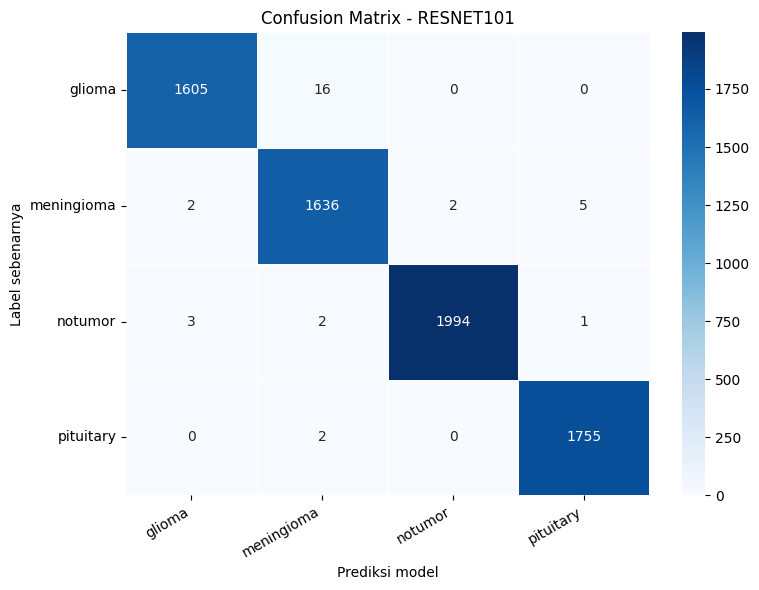

C:\Users\asus\AppData\Roaming\Python\Python314\site-packages\torchvision\models\googlenet.py:47: FutureWarning: The default weight initialization of GoogleNet will be changed in future releases of torchvision. If you wish to keep the old behavior (which leads to long initialization times due to scipy/scipy#11299), please set init_weights=True.
  warnings.warn(



HASIL GOOGLENET
Jumlah gambar eksternal: 7023
Accuracy: 0.7820 (78.20%)
Macro F1: 0.7736

Classification report:
              precision    recall  f1-score   support

      glioma       0.98      0.62      0.76      1621
  meningioma       0.68      0.91      0.78      1645
     notumor       0.71      0.99      0.83      2000
   pituitary       1.00      0.57      0.73      1757

    accuracy                           0.78      7023
   macro avg       0.84      0.77      0.77      7023
weighted avg       0.84      0.78      0.78      7023



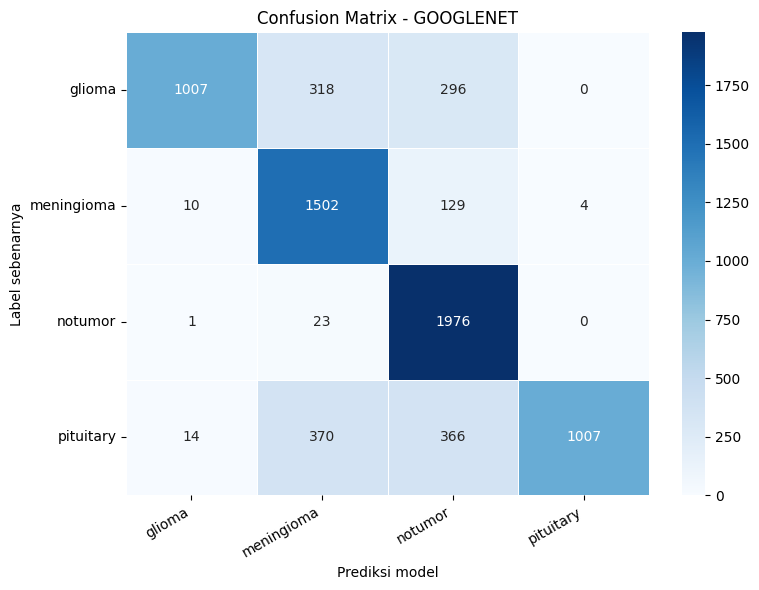


Ringkasan evaluasi data eksternal:
    model  jumlah_gambar_eksternal  accuracy  macro_f1
    vgg16                     7023  0.986900  0.986330
resnet101                     7023  0.995301  0.995110
googlenet                     7023  0.782002  0.773604


In [ ]:
from pathlib import Path
import json

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
from PIL import ImageOps

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from PIL import Image, ImageOps
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

EXTERNAL_DIR = Path(r"D:\Skripsi\external_test")
MODEL_DIR = Path(r"D:\Skripsi\results_final_padded_lr1e-3")

IMG_SIZE = 224
BATCH_SIZE = 32
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if not EXTERNAL_DIR.is_dir():
    raise FileNotFoundError(f"Folder data eksternal tidak ditemukan: {EXTERNAL_DIR}")

class_names_path = MODEL_DIR / "class_names.json"
if not class_names_path.is_file():
    raise FileNotFoundError(f"class_names.json tidak ditemukan: {class_names_path}")

with open(class_names_path, "r", encoding="utf-8") as f:
    class_names = json.load(f)

class ResizeWithBlackPadding:
    def __init__(self, size):
        self.size = (size, size)

    def __call__(self, image):
        image = image.convert("RGB")
        image.thumbnail(self.size, Image.Resampling.BILINEAR)

        pad_w = self.size[0] - image.width
        pad_h = self.size[1] - image.height
        left = pad_w // 2
        top = pad_h // 2

        return ImageOps.expand(
            image,
            border=(left, top, pad_w - left, pad_h - top),
            fill=(0, 0, 0),
        )

transform = transforms.Compose([
    ResizeWithBlackPadding(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

dataset = datasets.ImageFolder(EXTERNAL_DIR, transform=transform)

if len(dataset) == 0:
    raise ValueError(f"Tidak ada gambar yang ditemukan di {EXTERNAL_DIR}")

if dataset.classes != class_names:
    raise ValueError(
        "Nama atau urutan kelas folder eksternal tidak cocok dengan class_names.json.\n"
        f"Kelas di folder: {dataset.classes}\n"
        f"Kelas model: {class_names}"
    )

loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

print(f"Device: {DEVICE}")
print(f"Jumlah gambar eksternal: {len(dataset)}")
print(f"Urutan kelas: {class_names}")

def build_model(model_name, num_classes):
    if model_name == "vgg16":
        model = models.vgg16(weights=None)
        model.classifier[6] = nn.Linear(
            model.classifier[6].in_features,
            num_classes,
        )

    elif model_name == "resnet101":
        model = models.resnet101(weights=None)
        model.fc = nn.Linear(
            model.fc.in_features,
            num_classes,
        )

    elif model_name == "googlenet":
        model = models.googlenet(
            weights=None,
            aux_logits=False,
        )
        model.fc = nn.Linear(
            model.fc.in_features,
            num_classes,
        )

    else:
        raise ValueError(f"Nama model tidak dikenal: {model_name}")

    return model


def load_checkpoint(model, checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location=DEVICE)

    if isinstance(checkpoint, dict):
        for key in ("state_dict", "model_state_dict", "model"):
            if key in checkpoint and isinstance(checkpoint[key], dict):
                checkpoint = checkpoint[key]
                break

    # Menangani bobot yang disimpan menggunakan DataParallel.
    if checkpoint and all(key.startswith("module.") for key in checkpoint):
        checkpoint = {
            key.removeprefix("module."): value
            for key, value in checkpoint.items()
        }

    model.load_state_dict(checkpoint)
    model = model.to(DEVICE)
    model.eval()
    return model


y_true = [label for _, label in dataset.samples]
results = []

model_names = ("vgg16", "resnet101", "googlenet")

for name in model_names:
    checkpoint_path = MODEL_DIR / f"{name}_finetuned.pth"

    if not checkpoint_path.is_file():
        raise FileNotFoundError(f"Checkpoint tidak ditemukan: {checkpoint_path}")

    model = build_model(name, num_classes=len(class_names))
    model = load_checkpoint(model, checkpoint_path)

    predictions = []

    with torch.inference_mode():
        for images, _ in loader:
            images = images.to(DEVICE)
            outputs = model(images)

            if hasattr(outputs, "logits"):
                outputs = outputs.logits
            elif isinstance(outputs, tuple):
                outputs = outputs[0]

            batch_predictions = outputs.argmax(dim=1)
            predictions.extend(batch_predictions.cpu().tolist())

    accuracy = accuracy_score(y_true, predictions)
    macro_f1 = f1_score(
        y_true,
        predictions,
        labels=list(range(len(class_names))),
        average="macro",
        zero_division=0,
    )

    print(f"\n{'=' * 60}")
    print(f"HASIL {name.upper()}")
    print(f"Jumlah gambar eksternal: {len(dataset)}")
    print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
    print(f"Macro F1: {macro_f1:.4f}")
    print("\nClassification report:")
    print(classification_report(
        y_true,
        predictions,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0,
    ))

    cm = confusion_matrix(
        y_true,
        predictions,
        labels=list(range(len(class_names))),
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        linewidths=0.5,
        linecolor="white",
    )
    plt.title(f"Confusion Matrix - {name.upper()}")
    plt.xlabel("Prediksi model")
    plt.ylabel("Label sebenarnya")
    plt.xticks(rotation=30, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    results.append({
        "model": name,
        "jumlah_gambar_eksternal": len(dataset),
        "accuracy": accuracy,
        "macro_f1": macro_f1,
    })

summary = pd.DataFrame(results)

print("\nRingkasan evaluasi data eksternal:")
print(summary.to_string(index=False))